# Define morphological models with `neat.PhysTree`
The Class `neat.PhysTree` is used to define the physiological parameters of neuron models. It inherits from `neat.MorphTree` and thus has all its functionality. Just as `neat.MorphTree`, instances are initialized based on the standard `.swc` format:

In [52]:
from neat import PhysTree
ph_tree = PhysTree('morph/L23PyrBranco.swc')

## Defining physiological parameters

A `PhysTree` consists of `neat.PhysNode` instances, which inherit from `neat.MorphNode`. Compared to a `MorphNode`, a `PhysNode` has extra attributes (initialized to some default value) defining physiological parameters:

In [53]:
# specific membrance capacitance (uF/cm^2)
print('default c_m node 1:', ph_tree[1].c_m)
# axial resisitance (MOhm*cm)
print('default r_a node 1:', ph_tree[1].r_a)
# point-like shunt located at {'node': node.index, 'x': 1.} (uS)
print('default g_shunt node 1:', ph_tree[1].g_shunt)
# leak and ion channel currents, stored in a dict with
# key: 'channel_name', value: [g_max, e_rev]
print('default currents node 1:', ph_tree[1].currents)

default c_m node 1: 1.0
default r_a node 1: 9.999999999999999e-05
default g_shunt node 1: 0.0
default currents node 1: {}


It is not recommended, and for ion channels even forbidden, to set the parameters directly via the nodes. Rather, the parameters should be specified with associated functions of `PhysTree`. These functions accept a `node_arg` keyword argument, which allows selecting a specific set of nodes. Parameters, can be given as `float`, in which case all nodes in `node_arg` will be set to the same value, a `dict` of `{node.index: parameter_value}`, or a callable function where the input is the distance of the middle of the node (`loc = {'node': node.index, 'x': .5}`) to the soma and the output the parameter.

Let's use `PhysTree.set_physiology()` to set capacitance (1st argument) and axial resistance (2nd argument) in the whole tree:

In [54]:
ph_tree.set_physiology(lambda x: .8 if x < 60. else 1.6*.8, 100.*1e-6)

Here, we defined the capacitance to be $.8$ $\mu$F/cm$^2$ when the mid-point of the node is less than 60 $\mu$m from the soma and $1.6*.8$ $\mu$F/cm$^2$, a common factor to take dendritic spines into account. Axial resistance was set to a constant value throughout the tree.

To set ion channels (see the 'Ionchannels in NEAT' tutorial on how to create your own ion channels), we must create the ion channel instance first. Here, we'll set a default sodium and potassium channel:

In [55]:
from channelcollection_for_tutorial import Na_Ta, Kv3_1
# create the ion channel instances
na_chan = Na_Ta()
k_chan = Kv3_1()
# set the sodium channel only at the soma, with a reversal of 50 mV
ph_tree.add_channel_current(na_chan, 1.71*1e6, 50., node_arg=[ph_tree[1]])
# set the potassium channel throughout the dendritic tree, at 1/10th 
# of its somatic conductance, and with a reversal of -85 mV
gk_soma = 0.45*1e6
ph_tree.add_channel_current(k_chan, lambda x: gk_soma if x < .1 else gk_soma/10., -85.)

Now, we only have to set the leak current. We have two possibilities for this: (i) we could set the leak current by providing conductance and reversal in the standard way with `PhysTree.set_leak_current()` or (ii) with could fit the leak current to fix equilibrium potential and membrane time scale (if possible) with `PhysTree.fit_leak_current()`. We take the second option here:

In [56]:
# fit leak current to yield an equilibrium potential of -70 mV and
# a total membrane time-scale of 10 ms (with channel opening 
# probabilities evaluated at -70 mV)
ph_tree.fit_leak_current(-70., 10.)

## Inspecting the physiological parameters

We can now inspect the contents of various `PhysNode` instances:

In [57]:
# soma node
print(ph_tree[1])

PhysNode 1, Parent: None --- r_a = 0.0001 MOhm*cm, c_m = 0.8 uF/cm^2, v_ep = -70 mV, (g_Na_Ta = 1.71e+06 uS/cm^2, e_Na_Ta = 50 mV), (g_Kv3_1 = 450000 uS/cm^2, e_Kv3_1 = -85 mV), (g_L = 31.5408 uS/cm^2, e_L = -48.6388 mV)


In [58]:
# dendrite node
print(ph_tree[115])

PhysNode 115, Parent: 114 --- r_a = 0.0001 MOhm*cm, c_m = 1.28 uF/cm^2, v_ep = -70 mV, (g_Kv3_1 = 45000 uS/cm^2, e_Kv3_1 = -85 mV), (g_L = 123.193 uS/cm^2, e_L = -69.4148 mV)


Or, to get the full information on conductances and reversal potentials of membrane currents:

In [59]:
# soma node
print(ph_tree[1].currents)

{'Na_Ta': [1710000.0, 50.0], 'Kv3_1': [450000.0, -85.0], 'L': [np.float64(31.5408107318479), np.float64(-48.638804987272735)]}


In [60]:
# dendrite node
print(ph_tree[115].currents)

{'Kv3_1': [45000.0, -85.0], 'L': [np.float64(123.19344287327353), np.float64(-69.41475491536458)]}


## Active dendrites compared to closest passive version

Imagine we aim to investigate the role of active dendritic channels, and to that purpose want to compare the active dendritic tree with a passive version. We may compute the leak conductance of this "passified" tree as the sum of all ion channel conductance evaluate at the equilibrium potential. The equilibrium potentials is stored on the tree using `PhysTree.set_v_ep()`:

In [61]:
ph_tree.set_v_ep(-70.)

To obtain the passified tree, we use `PhysTree.as_passive_membrane()`. However, this function will overwrite the parameters of the original nodes, if we want to maintain the initial tree, we have to copy it first:

In [62]:
# copy the initial tree
ph_tree_pas = PhysTree(ph_tree)
# set to passive (except the soma)
ph_tree_pas.as_passive_membrane(node_arg=[n for n in ph_tree_pas if n.index != 1])

We can now inspect the nodes:

In [63]:
# soma node
print(ph_tree_pas[1])

PhysNode 1, Parent: None --- r_a = 0.0001 MOhm*cm, c_m = 0.8 uF/cm^2, v_ep = -70 mV, (g_Na_Ta = 1.71e+06 uS/cm^2, e_Na_Ta = 50 mV), (g_Kv3_1 = 450000 uS/cm^2, e_Kv3_1 = -85 mV), (g_L = 31.5408 uS/cm^2, e_L = -48.6388 mV)


In [64]:
# dendrite node
print(ph_tree_pas[115])

PhysNode 115, Parent: 114 --- r_a = 0.0001 MOhm*cm, c_m = 1.28 uF/cm^2, v_ep = -70 mV, (g_L = 128 uS/cm^2, e_L = -70 mV)


And the currents:

In [65]:
# soma node
print(ph_tree_pas[1].currents)

{'Na_Ta': [1710000.0, 50.0], 'Kv3_1': [450000.0, -85.0], 'L': [np.float64(31.5408107318479), np.float64(-48.638804987272735)]}


In [66]:
# dendrite node
print(ph_tree_pas[115].currents)

{'L': [np.float64(128.00000000000003), np.float64(-70.0)]}


Comparing this to the previously shown nodes of the full tree, we see that the dendrite nodes have been "passified".

## Computational tree

The computational tree in `PhysTree` works the same as in `MorphTree`, except that it's derivation also considers changes in physiological parameters, next to changes in morphological parameters.

In [67]:
ph_tree.set_comp_tree()
# compare number of nodes in computational tree and original tree
print('%d nodes in original tree'%(len(ph_tree)))
with ph_tree.as_computational_tree:
    print('%d nodes in computational tree'%(len(ph_tree)))

432 nodes in original tree
98 nodes in computational tree


Compare this to the number of nodes in the computational tree induced solely by the morphological parameters:

In [68]:
from neat import MorphTree
m_tree = MorphTree('morph/L23PyrBranco.swc')
m_tree.set_comp_tree()
with m_tree.as_computational_tree:
    print('%d nodes in computational `MorphTree`'%len(m_tree))

87 nodes in computational `MorphTree`


Note: only call this `PhysTree.set_comp_tree` when all physiological parameters have been set, and ***never*** change parameters stored at individual nodes when the computational tree is active, as this leads to the computational tree being inconsistent with the original tree.

# Preparing NEAT models for simulation
To simulate models from NEAT, we first need to compile the ion channels. NEAT's `IonChannel` class instances can generate their own code for .mod files or .nestml files, which are then compiled into either NEURON, NEST or Arbor. For this purpose, NEAT provides the `neatmodels` terminal command, which should be invoked as follows to prepare the models for this tutorial:

```
neatmodels install TutorialChannels -s neuron nest arbor -p channelcollection_for_tutorial.py
```

The simulators for which the models are compiled are selected with the `-s` flag, so that e.g. `-s neuron nest` skips Arbor if it is not installed. All installed models can be visualized with `neatmodels list -s neuron nest arbor`, and can also be uninstalled (i.e. `neatmodels uninstall {model name} -s {simulator}`).

Installed models can then be loaded into e.g. NEURON.

In [69]:
from neat import load_neuron_model
load_neuron_model('TutorialChannels')

Loading NEURON model 'TutorialChannels'
Found path: /Users/wybo/Code/NEAT_public/src/neat/simulations/neuron/tmp/TutorialChannels, loading mechanisms...
... already loaded.


## Simulating NEAT models in NEURON or Arbor

NEAT implements interfaces to the NEURON and Arbor simulators, so that models defined by neat-trees can be simulated with either simulator. To have access to this functionality, the NEURON simulator and its Python interface, or the Arbor simulator, need to be installed.

The class `neat.NeuronSimTree` implements the NEURON interface, and inherits from `neat.PhysTree`. Hence, a `NeuronSimTree` can be defined in the same way as a `PhysTree`. The class `neat.ArborSimTree` implements the Arbor interface with the same API (see below).

In [70]:
from neat import NeuronSimTree
sim_tree = NeuronSimTree('morph/L23PyrBranco.swc')
sim_tree.set_physiology(lambda x: .8 if x < 60. else 1.6*.8, 100.*1e-6)
# ... etc

## Copying trees

If a different type of tree is needed than the one originally defined, or simply a copy of the original tree, we can use the copy construct functionality of `NEAT`'s trees: we can instantiate any tree class based on any other tree instance, and only the attributes that are shared amongst both instances will be copied over. Since `NeuronSimTree` is a subclass of `PhysTree`, we end up with an identical tree, but with additional functions and associated attributes to simulate the associated NEURON model.

In [71]:
sim_tree = NeuronSimTree(ph_tree)


First, we must initialize the tree structure into hoc.

In [72]:
sim_tree.init_model(t_calibrate=100.)

We may then add inputs to the tree. NEAT implements a number of standard synapse types and current injections. Let's apply a DC current step to the soma and also give some input to a conductance-based dendritic synapse.

In [73]:
# somatic DC current step with amplitude = 0.100 nA, delay = 5. ms and duration = 50. ms
sim_tree.add_i_clamp((1.,.5), 0.010, 5., 50.)
# dendritic synapse with rise resp. decay times of .2 resp 3. ms and reversal of 0 mV
sim_tree.add_double_exp_synapse((115,.8), .2, 3., 0.)
# give the dendritic synapse a weight of 0.005 uS and connect it to an input spike train
sim_tree.set_spiketrain(0, 0.005, [20.,22.,28.,29.,30.])

We will record voltage at the somatic and dendritic site. Recording locations should be stored under the name 'rec locs'.

In [74]:
sim_tree.store_locs([(1,.5), (115,.8)], name='rec locs')

We can then run the model for $60$ ms and plot the results:

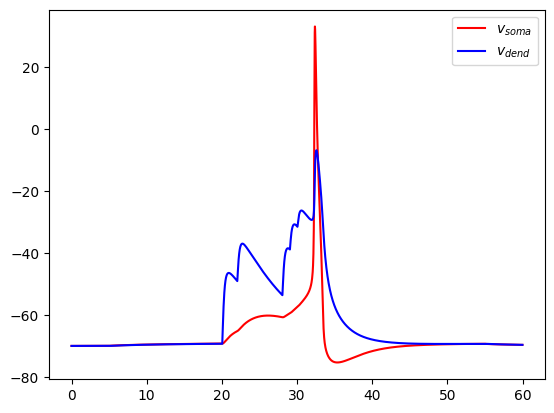

In [75]:
# simulate the model and delete all hoc-variables afterwards
res = sim_tree.run(60.)
sim_tree.delete_model()

# plot the results
import matplotlib.pyplot as pl
pl.plot(res['t'], res['v_m'][0], c='r', label=r'$v_{soma}$')
pl.plot(res['t'], res['v_m'][1], c='b', label=r'$v_{dend}$')
pl.legend(loc=0)
pl.show()

## Simulating the same model in Arbor

`neat.ArborSimTree` has the same API as `neat.NeuronSimTree`, so that the same simulation can be run in Arbor by only changing the tree class. We first load the Arbor mechanism catalogue with the tutorial channels. Note that only one NEAT catalogue can be loaded in Arbor at a time; loading another one replaces it.

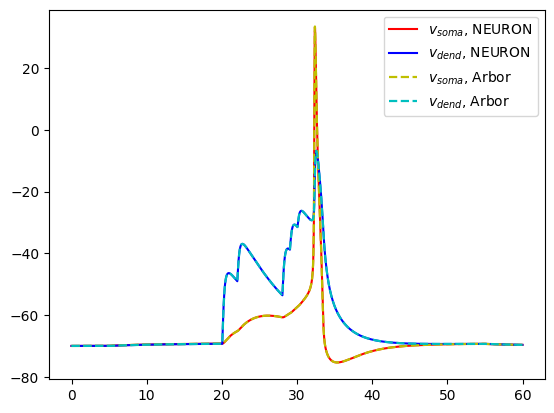

In [ ]:
from neat import load_arbor_model, ArborSimTree
load_arbor_model('TutorialChannels')

arb_tree = ArborSimTree(ph_tree)
arb_tree.init_model(t_calibrate=100.)
arb_tree.add_i_clamp((1.,.5), 0.010, 5., 50.)
arb_tree.add_double_exp_synapse((115,.8), .2, 3., 0.)
arb_tree.set_spiketrain(0, 0.005, [20.,22.,28.,29.,30.])
arb_tree.store_locs([(1,.5), (115,.8)], name='rec locs')
res_arb = arb_tree.run(60.)
arb_tree.delete_model()

# compare with the NEURON simulation
pl.plot(res['t'], res['v_m'][0], c='r', label=r'$v_{soma}$, NEURON')
pl.plot(res['t'], res['v_m'][1], c='b', label=r'$v_{dend}$, NEURON')
pl.plot(res_arb['t'], res_arb['v_m'][0], 'y--', lw=1.6, label=r'$v_{soma}$, Arbor')
pl.plot(res_arb['t'], res_arb['v_m'][1], 'c--', lw=1.6, label=r'$v_{dend}$, Arbor')
pl.legend(loc=0)
pl.show()

## User defined point-process

Note that it is very easy to add user defined point-process to the `NeuronSimTree` (for the `ArborSimTree`, see the source code of its `add_*()` functions). In fact, all any of the default functions to add point-process do, is defining a `neat.MorphLoc` based on the input, so that the point process is added at the right coordinates no matter whether the original or computational tree was active. All hoc sections are stored in the dict `self.sections` which has as keys the node indices. Hence, in pseudo code one would do:

```
loc = neat.MorphLoc((node.index, x-coordinate), sim_tree)

# define the point process at the correct location
pp = h.user_defined_point_process(sim_tree.sections[loc['node']](loc['x']))

# set its parameters
pp.param1 = val1
pp.param2 = val2
...

# store the point process (e.g. if it is a synapse in `sim_tree.syns`)
sim_tree.syns.append(pp)
```

# Evaluate impedance matrices with `neat.GreensTree`

The class `neat.GreensTree` inherits from `neat.PhysTree` and implements Koch's algorithm [-@Koch1984] to calculate impedances in the Fourrier domain. For a given input current of frequency $\omega$ at location $x$, the impedance gives the linearized voltage response at a location $x^{\prime}$:
\begin{align}
v_{x^{\prime}}(\omega) = z_{x^{\prime}x}(\omega) \, i_x(\omega).
\end{align}
Applying the inverse Fourrier transform yields a convolution in the the time domain:
\begin{align}
v_{x^{\prime}}(t) = z_{x^{\prime}x}(t) \ast i_x(t),
\end{align}
with we call $z_{x^{\prime}x}(t) = FT^{-1} \left(  z_{x^{\prime}x}(\omega) \right)$ the impedance kernel. The steady state impedance is then:
\begin{align}
z_{x^{\prime}x} = \int_0^{\infty} \mathrm{d}t \, z_{x^{\prime}x}(t) = z_{x^{\prime}x}(\omega = 0).
\end{align}

## Computing an impedance kernel

To compute an impedance kernel, we first have to initialize the `GreensTree`:

In [76]:
from neat import GreensTree
greens_tree = GreensTree(ph_tree)

For the calculation to proceed efficiently, `GreensTree` first sets effective, frequency-dependent boundary conditions for each cylindrical section. Hence we must specify the frequencies at which we want to evaluate impedances. If we aim to also compute temporal kernels, `neat.FourierQuadrature` is a handy tool to obtain the correct frequencies. Suppose for instance that we aim to compute an impedance kernels from $0$ to $50$ ms:

In [77]:
from neat import FourierQuadrature
import numpy as np
# create a FourierQuadrature instance with the temporal array on which to evaluate the impedance kernel
t_arr = np.linspace(0.,50.,1000)
ft = FourierQuadrature(t_arr)
# appropriate frequencies are stored in `ft.s`
# set the boundary condition for cylindrical segments in `greens_tree`
greens_tree.set_impedance(ft.s)

We can now compute for instance the impedance kernel between dendritic and somatic site:

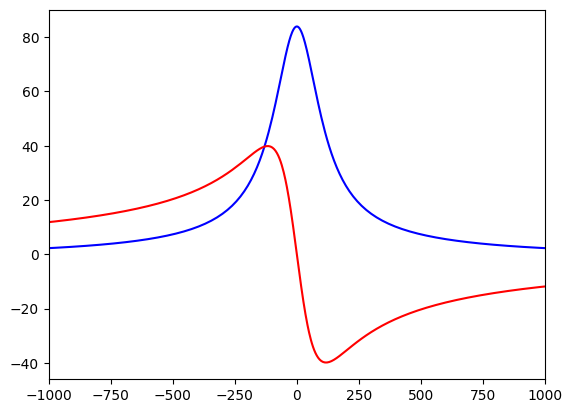

In [78]:
z_trans = greens_tree.calc_zf((1,.5), (115,.8))

# plot the kernel
pl.plot(ft.s.imag, z_trans.real, 'b')
pl.plot(ft.s.imag, z_trans.imag, 'r')
pl.xlim((-1000.,1000.))
pl.show()

We can also obtain this kernel in the time domain using the `GreensTreeTime` object:

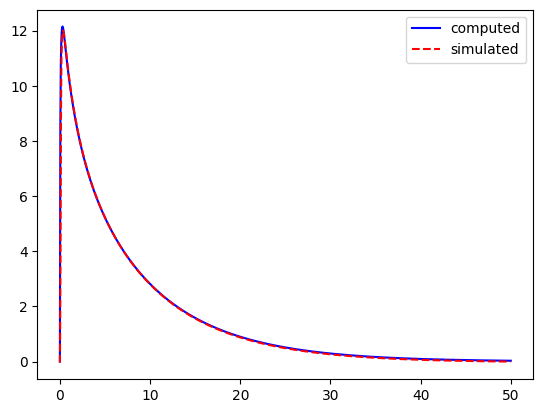

In [79]:
# time domain kernel
from neat import GreensTreeTime
gtt = GreensTreeTime(ph_tree)
gtt.set_impedance(t_arr)
zt = gtt.calc_zt((1,.5), (115,.8), compute_time_derivative=False)

# comparison with NEURON simulation
sim_tree.init_model(t_calibrate=300.)
i_amp, i_dur = 0.001, 0.1
sim_tree.add_i_clamp((115,.8), i_amp, 0., i_dur)
res = sim_tree.run(50.)
sim_tree.delete_model()
res['v_m'] -= res['v_m'][:,-1]
res['v_m'] /= (i_amp*i_dur)

# plot the kernel
pl.plot(t_arr, zt, 'b', label='computed')
pl.plot(res['t'], res['v_m'][0], 'r--', label='simulated')
pl.legend(loc=0)
pl.show()

## Computing the impedance matrix

While `GreensTree.calc_zf()` could be used to explicitely compute the impedance matrix, `GreensTree.calc_impedance_matrix()` uses the symmetry and transitivity properties of impedance kernels to further optimize the calculation.

In [80]:
z_locs = [(1,.5), (115,.8)]
z_mat = greens_tree.calc_impedance_matrix(z_locs)

This matrix has shape ``(len(ft.s), len(z_locs), len(z_locs))``. The zero-frequency component is at `ft.ind_0s`. Hence, the following gives the steady state impedance matrix:

In [81]:
print(z_mat[ft.ind_0s])

[[ 88.07091747+0.j  83.93186356+0.j]
 [ 83.93186356+0.j 183.59769195+0.j]]


# Simplify a model with `neat.CompartmentFitter`

The class `neat.CompartmentFitter` is used to obtain simplified compartmental models, where the parameters of the compartments are optimized to reproduce voltages at any set of locations on the morphology. It is initialized based on a `neat.PhysTree`:

In [82]:
from neat import CompartmentFitter
c_fit = CompartmentFitter(ph_tree)


>>>> Cache file for CompartmentFitter:
    neatcache/_cache_b80d98f3e873c5a168e383cad92be3706ce4673e3ef50cd55b9e66529d75e49a.p
<<<<


The function `CompartmentFitter.fit_model()` then returns a `neat.CompartmentTree` object defining the simplified model, with the parameters of the optimized compartments:

In [83]:
# compute a simplified tree containing a somatic and dendritic compartment
f_locs = [(1,.5), (115,.8)]
c_tree, c_locs = c_fit.fit_model(f_locs, use_all_channels_for_passive=False)

One way to understand whether the reduction will be faithful, is to check whether the passive reduced model reproduces the same impedance kernels as the full model. The `check_passive()` function of `neat.CompartmentFitter` allows the comparison of these kernels between full and reduced models:

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


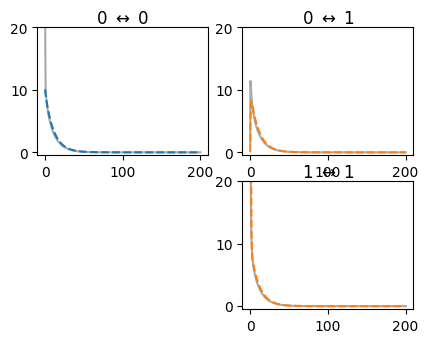

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


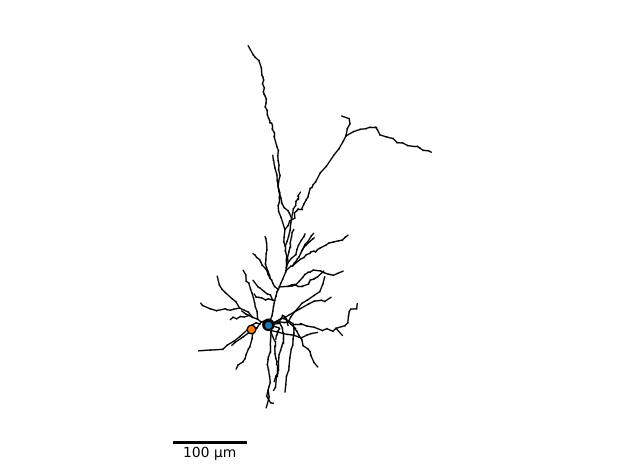

In [84]:
c_fit.check_passive(f_locs, use_all_channels_for_passive=False)

## The simplified model `neat.CompartmentTree`

Each `neat.CompartmentNode` in the `CompartmentTree` stores the optimized parameters of the compartment, and the coupling conductance with it's parent node.

In [85]:
print(c_tree)

>>> CompartmentTree
    CompartmentNode 0, Parent: None --- loc_idx = 0, g_c = 0.0 uS, ca = 9.914229970918552e-05 uF, e_eq = -70.0000000000006 mV, (g_L = 0.0091883014762325 uS, e_L = -68.82253558506142 mV), (g_Na_Ta = 14.378466892351303 uS, e_Na_Ta = 50.0 mV), (g_Kv3_1 = 7.000477231569277 uS, e_Kv3_1 = -85.0 mV)
    CompartmentNode 1, Parent: 0 --- loc_idx = 1, g_c = 0.009224434868094789 uS, ca = 4.268326527291403e-06 uF, e_eq = -70.0000000000006 mV, (g_L = 0.0004110344833249026 uS, e_L = -69.71819327183258 mV), (g_Na_Ta = 6.712302472717763e-12 uS, e_Na_Ta = 50.0 mV), (g_Kv3_1 = 0.07229641499493164 uS, e_Kv3_1 = -85.0 mV)


To keep track of the mapping between compartments and locations, each `CompartmentNode` also has a `loc_idx` attribute, containing the index of the location in the original list given to `CompartmentFitter.fit_model()` (here `f_locs`) to which the compartment is fitted:

In [86]:
# node 0 corresponds to location 0 in `f_locs`
print('node index: %d, loc index: %d'%(c_tree[0].index, c_tree[0].loc_idx))
# node 1 corresponds to location 1 in `f_locs`
print('node index: %d, loc index: %d'%(c_tree[1].index, c_tree[1].loc_idx))

node index: 0, loc index: 0
node index: 1, loc index: 1


Here, these indices correspond, but in general there is ***no*** guarantee this will be the case. A list of 'fake' locations for the compartmental model can also be obtained. These locations contain nothing but the node index and an x-coordinate without meaning.

In [87]:
c_locs = c_tree.get_equivalent_locs()
print(c_locs[0], c_locs[1])

(0, 0.5) (1, 0.5)


# Simulating simplified models

The simplified model can be simulated in NEURON, NEST and Arbor. We may then check whether our simplification was successful by running the same simulation for the full and reduced models.

## NEURON

To simulate the simplified model in NEURON, we create a `neat.NeuronCompartmentTree` from the `neat.CompartmentTree`. It has the same API as `neat.NeuronSimTree`:

In [88]:
from neat import NeuronCompartmentTree
c_sim_tree = NeuronCompartmentTree(c_tree)

We simulate the full model with the `NeuronSimTree` defined above, and the simplified model with the `NeuronCompartmentTree`:

In [89]:
# initialize, run and delete the full model, set input locations as stored in `f_locs`
sim_tree.init_model(t_calibrate=100.)
sim_tree.add_i_clamp(f_locs[0], .01, 5., 50.)
sim_tree.add_double_exp_synapse(f_locs[1], .2, 3., 0.)
sim_tree.set_spiketrain(0, 0.002, [20.,22.,28.,28.5,29.,30.,31.])
sim_tree.store_locs(f_locs, name='rec locs')
res_full = sim_tree.run(60.)
sim_tree.delete_model()

# initialize and run the simplified model, set input locations as stored in `c_locs`
c_sim_tree.init_model(t_calibrate=100.)
c_sim_tree.add_i_clamp(c_locs[0], 0.01, 5., 50.)
c_sim_tree.add_double_exp_synapse(c_locs[1], .2, 3., 0.)
c_sim_tree.set_spiketrain(0, 0.002, [20.,22.,28.,28.5,29.,30.,31.])
c_sim_tree.store_locs(c_locs, name='rec locs')
res_reduced = c_sim_tree.run(60.)
# print the hoc topology of the reduced model
from neuron import h
h.topology()
# delete the reduced model
c_sim_tree.delete_model()


|-|       0(0-1)
  `|       1(0-1)



## NEST

The simplified model can also be exported to NEST. To this purpose, we first import NEST and load the NEST model featuring the tutorial channels

In [90]:
import nest
dt = 0.1
nest.ResetKernel()
nest.SetKernelStatus(dict(resolution=dt))

from neat import load_nest_model
load_nest_model("TutorialChannels")


Jun 16 10:12:50 SimulationManager::set_status [Info]: 
    Temporal resolution changed from 0.1 to 0.1 ms.


Cannot load crlibm extension. The imath functions will not be available.



Jun 16 10:12:52 Install [Info]: 
    loaded module TutorialChannels_module


We can then use a `NestCompartmentTree` to translate the NEAT compartment tree to NEST

In [91]:
from neat import NestCompartmentTree
c_tree_nest = NestCompartmentTree(c_tree)
cm = c_tree_nest.init_model("TutorialChannels", 1) # equivalent of nest.Create()

0 {'g_L': np.float64(0.0091883014762325), 'e_L': np.float64(-68.82253558506142), 'C_m': np.float64(0.09914229970918552), 'g_C': 0.0, 'gbar_Na_Ta': np.float64(14.378466892351303), 'gbar_Kv3_1': np.float64(7.000477231569277), 'e_Na_Ta': np.float64(50.0), 'e_Kv3_1': np.float64(-85.0), 'v_comp': np.float64(-70.0000000000006), 'h_Na_Ta': array(0.66075637), 'm_Na_Ta': array(0.00703632), 'm_Kv3_1': array(0.00010681)}
1 {'g_L': np.float64(0.0004110344833249026), 'e_L': np.float64(-69.71819327183258), 'C_m': np.float64(0.004268326527291403), 'g_C': np.float64(0.009224434868094789), 'gbar_Na_Ta': np.float64(6.712302472717763e-12), 'gbar_Kv3_1': np.float64(0.07229641499493164), 'e_Na_Ta': np.float64(50.0), 'e_Kv3_1': np.float64(-85.0), 'v_comp': np.float64(-70.0000000000006), 'h_Na_Ta': array(0.66075637), 'm_Na_Ta': array(0.00703632), 'm_Kv3_1': array(0.00010681)}


We implement the same stimulation in NEST using NEST-specific simulation control.

In [92]:
# NEST-specific simulation control
# adding receptors
cm.receptors = [
    {
        "comp_idx": 0,
        "receptor_type": "curr_in",
    },
    {
        "comp_idx": 1,
        "receptor_type": "i_AMPA",
        "params": {"e_AMPA": 0.0, "tau_r_AMPA": 0.2, "tau_d_AMPA": 3.0},
    },
]
# connect spike input to i_AMPA receptor
sg = nest.Create("spike_generator", 1, {"spike_times": [20.,22.,28.,28.5,29.,30.,31.]})
nest.Connect(
    sg, cm,
    syn_spec={
        "synapse_model": "static_synapse",
        "weight": 0.002,
        "delay": dt,
        "receptor_type": 1,
    },
)
# connect DC current to curr_in receptor
dc = nest.Create("step_current_generator", 1, 
    params={
        "amplitude_times": [5.,50.], 
        "amplitude_values": [0.01,0.],
    }
)
nest.Connect(
    dc, cm,
    syn_spec={
        "synapse_model": "static_synapse",
        "weight": 1.0,
        "delay": 0.1,
        "receptor_type": 0,
    }
)
# voltage recording
mm = nest.Create(
    "multimeter",
    1,
    {
        "record_from": ["v_comp0", "v_comp1"], 
        "interval": dt,
    },
)
nest.Connect(mm, cm)

# simulate
nest.Simulate(60.0)

res_nest = nest.GetStatus(mm, "events")[0]


Jun 16 10:12:52 NodeManager::prepare_nodes [Info]: 
    Preparing 4 nodes for simulation.

Jun 16 10:12:52 SimulationManager::start_updating_ [Info]: 
    Number of local nodes: 4
    Simulation time (ms): 60
    Number of OpenMP threads: 1
    Number of MPI processes: 1

Jun 16 10:12:52 SimulationManager::run [Info]: 
    Simulation finished.


## Arbor

To simulate the simplified model in Arbor, we create a `neat.ArborCompartmentTree` from the `neat.CompartmentTree`. It has the same API as `neat.ArborSimTree`, so that the simulation is defined in the same way as for NEURON (the catalogue with the tutorial channels was already loaded above):

In [ ]:
from neat import ArborCompartmentTree
c_arb_tree = ArborCompartmentTree(c_tree)

c_arb_tree.init_model(t_calibrate=100.)
c_arb_tree.add_i_clamp(c_locs[0], 0.01, 5., 50.)
c_arb_tree.add_double_exp_synapse(c_locs[1], .2, 3., 0.)
c_arb_tree.set_spiketrain(0, 0.002, [20.,22.,28.,28.5,29.,30.,31.])
c_arb_tree.store_locs(c_locs, name='rec locs')
res_arbor = c_arb_tree.run(60.)
c_arb_tree.delete_model()

## Comparison

We compare somatic and dendritic voltages in the full model and in the simplified models simulated with the three simulators:

In [ ]:
pl.plot(res_full['t'], res_full['v_m'][0], c='DarkGrey', label='full') # soma full model, NEURON
pl.plot(res_full['t'], res_full['v_m'][1], c='DarkGrey') # dendrite full model, NEURON
pl.plot(res_reduced['t'], res_reduced['v_m'][0], 'r--', lw=1.6, label='reduced, soma') # soma reduced model, NEURON
pl.plot(res_reduced['t'], res_reduced['v_m'][1], 'b--', lw=1.6, label='reduced, dend') # dendrite reduced model, NEURON
pl.plot(res_nest['times'], res_nest['v_comp0'], 'r:', lw=2.6, label='nest, soma') # soma reduced model, NEST
pl.plot(res_nest['times'], res_nest['v_comp1'], 'b:', lw=2.6, label='nest, dend') # dendrite reduced model, NEST
pl.plot(res_arbor['t'], res_arbor['v_m'][0], 'r-.', lw=1.2, label='arbor, soma') # soma reduced model, Arbor
pl.plot(res_arbor['t'], res_arbor['v_m'][1], 'b-.', lw=1.2, label='arbor, dend') # dendrite reduced model, Arbor

pl.legend(loc=0)
pl.show()